<a href="https://colab.research.google.com/github/abrandonwang/text-to-sound/blob/main/latent_diffusion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

!mkdir -p /content/data
!cp /content/drive/MyDrive/text-to-sound/data/* /content/data/
!ls -lh /content/data

latents = "/content/drive/MyDrive/text-to-sound/data/latents.npy"
clap_audio = "/content/drive/MyDrive/text-to-sound/data/clap_audio.npy"
clap_text = "/content/drive/MyDrive/text-to-sound/data/clap_text.npy"
CKPT = "/content/drive/MyDrive/text-to-sound/checkpoints/"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
total 1.4G
-rw------- 1 root root 1.3M Nov  8 01:08 captions_dev.csv
-rw------- 1 root root  25M Nov  8 01:08 clap_audio.npy
-rw------- 1 root root 125M Nov  8 01:08 clap_text.npy
-rw------- 1 root root  132 Nov  8 01:08 latent_scale.npy
-rw------- 1 root root 249M Nov  8 01:08 latents.npy
-rw------- 1 root root 995M Nov  8 01:08 mels.npy
-rw------- 1 root root  136 Nov  8 01:08 mel_stats.npy
-rw------- 1 root root 952K Nov  8 01:08 meta.csv


In [1]:
import torch
import glob
import pandas as pd
import os
from IPython.display import Audio, display
import librosa, librosa.display
import matplotlib.pyplot as plt
import numpy as np
import random
!test -d BigVGAN || git clone -q https://github.com/NVIDIA/BigVGAN
!sed -i 's/proxies: Optional\[Dict\],/proxies: Optional[Dict] = None,/; s/resume_download: bool,/resume_download: bool = False,/' BigVGAN/bigvgan.py
!grep -n "proxies\|resume_download" BigVGAN/bigvgan.py
import sys; sys.path.insert(0, "BigVGAN")
import torch, bigvgan
from tqdm.auto import tqdm
from torch.utils.data import Dataset, DataLoader, Subset
import torch.nn.functional as F
import math
import torch.nn as nn
from transformers import ClapModel, ClapProcessor
import copy
%matplotlib inline
import glob, random, numpy as np, pandas as pd, torch
from torch.utils.data import Dataset, DataLoader
device = "cuda"
vocoder = bigvgan.BigVGAN.from_pretrained("nvidia/bigvgan_v2_22khz_80band_256x", use_cuda_kernel = False)
vocoder.remove_weight_norm()
vocoder = vocoder.eval().to(device)
print(vocoder.h.sampling_rate)

DATA = "/content/data/"
mels = np.load(DATA + "mels.npy", mmap_mode = "r")
stats = np.load(DATA + "mel_stats.npy")
MIN, MAX = stats[0], stats[1]
meta = pd.read_csv(DATA + "meta.csv")

422:        proxies: Optional[Dict] = None,
423:        resume_download: bool = False,
444:                proxies=proxies,
445:                resume_download=resume_download,
476:                proxies=proxies,
477:                resume_download=resume_download,


config.json:   0%|          | 0.00/1.41k [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:190: UserWarning: The `resume_download` argument is deprecated and ignored in `hf_hub_download`. Downloads always resume whenever possible.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:145: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


Loading weights from nvidia/bigvgan_v2_22khz_80band_256x


bigvgan_generator.pt: reconstructing file:   0%|          |  0.00B /  449MB            

bigvgan_generator.pt: downloading bytes:           |  0.00B            

Removing weight norm...
22050


FileNotFoundError: [Errno 2] No such file or directory: '/content/data/mels.npy'

In [ ]:
class Autoencoder(nn.Module):
  def __init__(self):
    super().__init__()
    self.encoder = nn.Sequential(
      nn.Conv2d(1, 64, 3, 1, 1),
      nn.SiLU(),
      nn.Conv2d(64, 64, 3, 1, 1),
      nn.SiLU(),
      nn.Conv2d(64, 128, 3, 2, 1),
      nn.SiLU(),
      nn.Conv2d(128, 128, 3, 1, 1),
      nn.SiLU(),
      nn.Conv2d(128, 256, 3, 2, 1),
      nn.SiLU(),
      nn.Conv2d(256, 256, 3, 1, 1),
      nn.SiLU(),
      nn.Conv2d(256, 8, 3, 1, 1),
    )
    self.decoder = nn.Sequential(
        nn.Conv2d(4, 256, 3, 1, 1),
        nn.SiLU(),
        nn.Conv2d(256, 256, 3, 1, 1),
        nn.SiLU(),
        nn.Upsample(scale_factor = 2),
        nn.Conv2d(256, 128, 3, 1, 1),
        nn.SiLU(),
        nn.Conv2d(128, 128, 3, 1, 1),
        nn.SiLU(),
        nn.Upsample(scale_factor = 2),
        nn.Conv2d(128, 64, 3, 1, 1),
        nn.SiLU(),
        nn.Conv2d(64, 64, 3, 1, 1),
        nn.SiLU(),
        nn.Conv2d(64, 1, 3, 1, 1),
    )
  def forward(self, x):
    mu, logvar = self.encoder(x).chunk(2, dim = 1)
    z = mu + torch.exp(0.5 * logvar) * torch.randn_like(mu)
    return self.decoder(z), mu, logvar

model = Autoencoder().to(device)
model.load_state_dict(torch.load(CKPT + "/vae_gan2.pt"))

<All keys matched successfully>

In [ ]:
SCALE = 0.6863

meta = pd.read_csv(DRIVE + "data/meta.csv")
tr = (meta.split == "train").values
c_lat = np.load(DRIVE + "data/latents.npy")[tr]
c_aud = np.load(DRIVE + "data/clap_audio.npy")[tr]
c_txt = np.load(DRIVE + "data/clap_text.npy")[tr]

shards = [np.load(f) for f in sorted(glob.glob(DRIVE + "data/fsd/shard_*.npz"))]
f_lat = np.concatenate([s["latents"] for s in shards])
f_aud = np.concatenate([s["clap_audio"] for s in shards])
f_txt = np.concatenate([s["clap_text"] for s in shards])

lat = np.concatenate([c_lat, f_lat]).astype(np.float16)
aud = np.concatenate([c_aud, f_aud]).astype(np.float32)
txt = np.concatenate([c_txt, f_txt]).astype(np.float32)
print("clotho", len(c_lat), "| fsd", len(f_lat), "| total", len(lat))

class LatentDataset(Dataset):
    def __init__(self, lat, aud, txt):
        self.lat, self.aud, self.txt = lat, aud, txt
    def __len__(self):
        return len(self.lat)
    def __getitem__(self, i):
        z = torch.from_numpy(self.lat[i]).float() * SCALE
        if random.random() < 0.5:
            c = torch.from_numpy(self.aud[i])
        else:
            c = torch.from_numpy(self.txt[i, random.randrange(5)])
        return z, c / c.norm()

ds = LatentDataset(lat, aud, txt)
loader = DataLoader(ds, batch_size = 64, shuffle = True, num_workers = 0, drop_last = True)

In [ ]:
T = 1000
betas = torch.linspace(0.0001, 0.02, T).to(device)
alphas = 1 - betas
alpha_bar =  torch.cumprod(alphas, dim = 0)

def add_noise(x0, t):
    noise = torch.randn_like(x0)
    a = alpha_bar[t]
    a = a.view(-1, 1, 1, 1)
    noisy = torch.sqrt(a) * x0 + torch.sqrt(1 - a) * noise
    return noisy, noise

def time_embedding(t, dim = 32):
    half = dim // 2
    freqs = torch.exp(-math.log(10000) * torch.arange(half, device = t.device) / half)
    args = t[:, None].float() * freqs[None, :]
    return torch.cat([torch.sin(args), torch.cos(args)], dim = 1)

class ResBlock(nn.Module):
    def __init__(self, in_ch, out_ch, t_dim = 128):
        super().__init__()
        self.norm1 = nn.GroupNorm(32, in_ch)
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, padding = 1)
        self.t_proj = nn.Linear(t_dim, out_ch)
        self.norm2 = nn.GroupNorm(32, out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, padding = 1)
        self.act = nn.SiLU()
        self.skip = nn.Conv2d(in_ch, out_ch, 1) if in_ch != out_ch else nn.Identity()

    def forward(self, x, t_emb):
        h = self.conv1(self.act(self.norm1(x)))
        h = h + self.t_proj(t_emb)[:, :, None, None]
        h = self.conv2(self.act(self.norm2(h)))
        return h + self.skip(x)

class Attention(nn.Module):
    def __init__(self, ch, heads = 8):
        super().__init__()
        self.norm = nn.GroupNorm(32, ch)
        self.attn = nn.MultiheadAttention(ch, heads, batch_first = True)

    def forward(self, x):
        B, C, H, W = x.shape
        h = self.norm(x).flatten(2).transpose(1, 2)
        h, _ = self.attn(h, h, h)
        h = h.transpose(1, 2).reshape(B, C, H, W)
        return x + h

class UNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.cond_proj = nn.Linear(512, 128)
        self.inp = nn.Conv2d(4, 64, 3, padding = 1)
        self.block1 = ResBlock(64, 64)
        self.down1 = nn.Conv2d(64, 64, 3, stride = 2, padding = 1)
        self.block2 = ResBlock(64, 128)
        self.down2 = nn.Conv2d(128, 128, 3, stride = 2, padding = 1)
        self.block3 = ResBlock(128, 256)
        self.mid = ResBlock(256, 512)
        self.attn = Attention(512)
        self.up = nn.Upsample(scale_factor = 2)
        self.block4 = ResBlock(768, 256)
        self.block5 = ResBlock(384, 128)
        self.block6 = ResBlock(192, 64)
        self.out_norm = nn.GroupNorm(32, 64)
        self.out = nn.Conv2d(64, 4, 1)

    def forward(self, x, t, c):
        t_emb = time_embedding(t, dim = 128) + self.cond_proj(c)
        x = self.inp(x)
        d1 = self.block1(x, t_emb)
        h = self.down1(d1)
        d2 = self.block2(h, t_emb)
        h = self.down2(d2)
        d3 = self.block3(h, t_emb)
        h = self.mid(d3, t_emb)
        h = self.attn(h)
        h = torch.cat([h, d3], dim = 1)
        h = self.block4(h, t_emb)
        h = self.up(h)
        h = torch.cat([h, d2], dim = 1)
        h = self.block5(h, t_emb)
        h = self.up(h)
        h = torch.cat([h, d1], dim = 1)
        h = self.block6(h, t_emb)
        return self.out(nn.functional.silu(self.out_norm(h)))

model = UNet().to(device)
x = torch.randn(2, 4, 20, 64, device = device)
t = torch.randint(0, T, (2,), device = device)
c = torch.randn(2, 512, device = device)
print(model(x, t, c).shape)
print(sum(p.numel() for p in model.parameters()))

torch.Size([2, 4, 20, 64])
9742148


In [ ]:
model = UNet().to(device)
opt = torch.optim.Adam(model.parameters(), lr = 2e-4)
ema = copy.deepcopy(model)
EPOCHS = 50
for epoch in range(EPOCHS):
    total = 0
    for lat, clap in tqdm(loader):
        lat = lat.to(device)
        c = clap.to(device)
        mask = torch.rand(c.shape[0], device = device) < 0.1
        c[mask] = 0
        t = torch.randint(0, T, (lat.shape[0],), device = device)
        noisy, noise = add_noise(lat, t)
        pred = model(noisy, t, c)
        loss = F.mse_loss(pred, noise)
        opt.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()

        with torch.no_grad():
          for p_ema, p in zip(ema.parameters(), model.parameters()):
            p_ema.mul_(0.999).add_(p, alpha = 0.001)

        total = total + loss.item()
    print(epoch, total / len(loader))
    if (epoch + 1) % 25 == 0:
      torch.save(ema.state_dict(), CKPT + f"unet_v3_ema_{epoch + 1}.pt")
    torch.save(model.state_dict(), CKPT + "unet_v3.pt")
    torch.save(ema.state_dict(), CKPT + "unet_v3_ema.pt")
print(torch.cuda.max_memory_allocated() / 1e9, "GB")

  0%|          | 0/714 [00:00<?, ?it/s]

0 0.14261883225667626


  0%|          | 0/714 [00:00<?, ?it/s]

1 0.11137878878109929


  0%|          | 0/714 [00:00<?, ?it/s]

2 0.10593470634699535


... (90 outputs left out)

  0%|          | 0/714 [00:00<?, ?it/s]

48 0.09697349183783144


  0%|          | 0/714 [00:00<?, ?it/s]

49 0.09602722952648454
2.286368768 GB


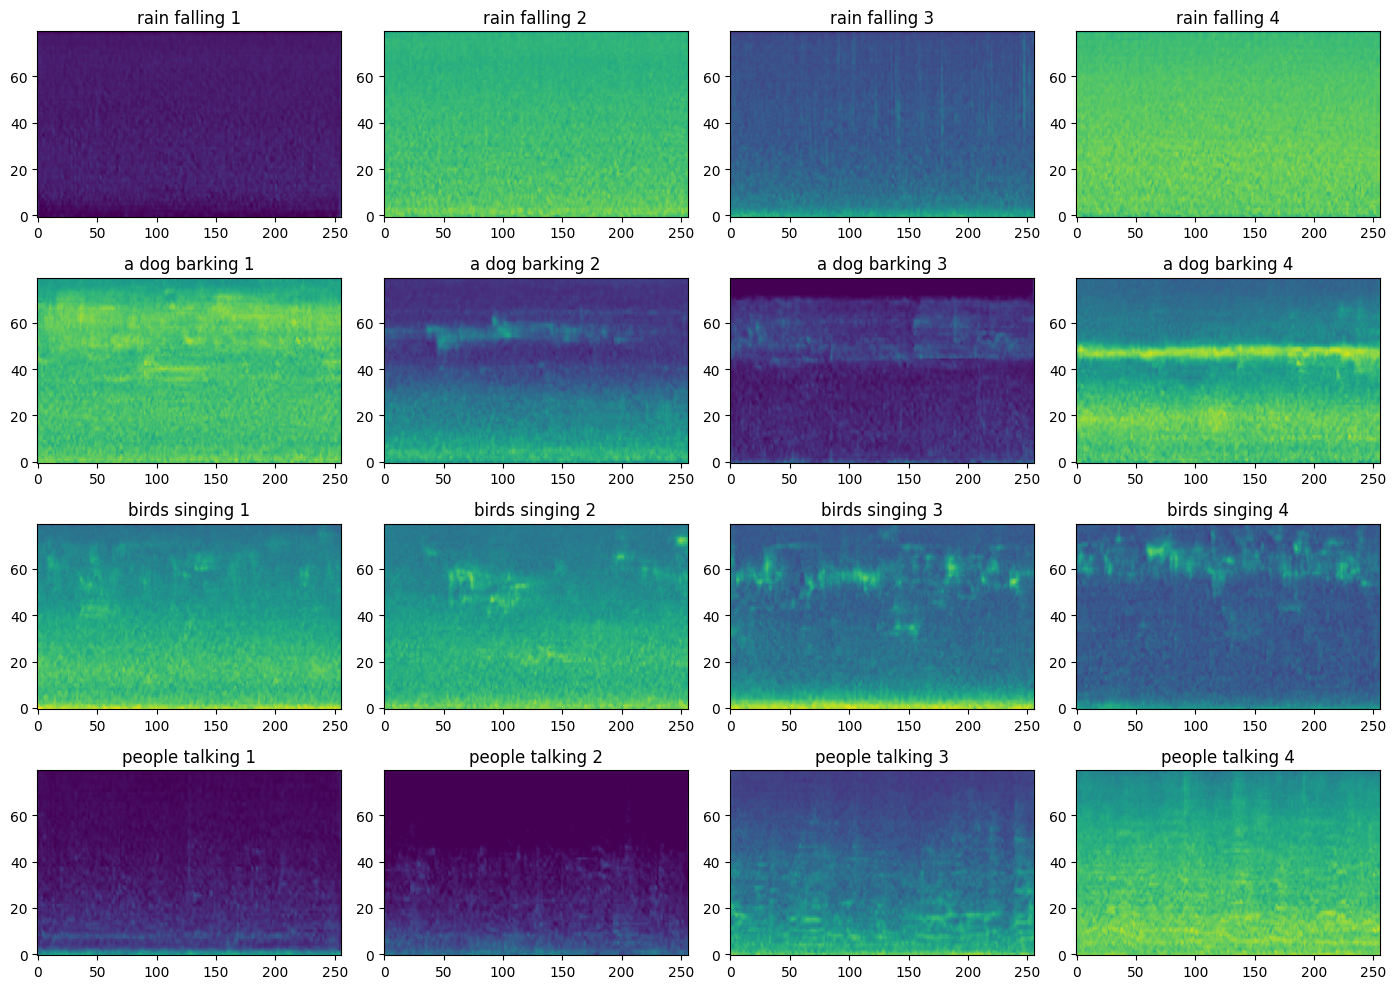

rain falling 1


rain falling 2


rain falling 3


rain falling 4


a dog barking 1


a dog barking 2


... (6 outputs left out)

people talking 1


people talking 2


people talking 3


people talking 4


In [ ]:
prompts = ["rain falling", "a dog barking", "birds singing", "people talking"]
with torch.inference_mode():
    t_in = proc(text = prompts, return_tensors = "pt", padding = True).to(device)
    c = clap_model.get_text_features(**t_in).pooler_output
    c = F.normalize(c, dim = 1)
c = c.repeat_interleave(4, dim = 0)
c_none = torch.zeros_like(c)
w = 3
N = c.shape[0]

ema = UNet().to(device)
ema.load_state_dict(torch.load(CKPT + "unet_v3_ema.pt", map_location = device))
ema.eval()
vae = Autoencoder().to(device)
vae.load_state_dict(torch.load(CKPT + "vae_gan2.pt", map_location = device))
vae.eval()

x = torch.randn(N, 4, 20, 64, device = device)
with torch.no_grad():
    for t in range(T - 1, -1, -1):
        t_batch = torch.full((N,), t, device = device)
        eps_none = ema(x, t_batch, c_none)
        eps_label = ema(x, t_batch, c)
        eps = eps_none + w * (eps_label - eps_none)
        mean = (1 / torch.sqrt(alphas[t])) * (x - (betas[t] / torch.sqrt(1 - alpha_bar[t])) * eps)
        if t > 0:
            x = mean + torch.sqrt(betas[t]) * torch.randn_like(x)
        else:
            x = mean
    mel = vae.decoder(x / 0.6863).clamp(-1, 1)
    m = ((mel + 1) / 2) * (MAX - MIN) + MIN
    wav = vocoder(m.squeeze(1))

fig, axes = plt.subplots(4, 4, figsize = (14, 10))
for i in range(N):
    ax = axes[i // 4, i % 4]
    ax.imshow(mel[i].squeeze().cpu().numpy(), origin = "lower", aspect = "auto", vmin = -1, vmax = 1)
    ax.set_title(f"{prompts[i // 4]} {i % 4 + 1}")
plt.tight_layout()
plt.show()

for i in range(N):
    print(prompts[i // 4], i % 4 + 1)
    display(Audio(wav[i].squeeze().cpu().numpy(), rate = 22050))